In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Week 4: EDA Deep Dive")
print("Libraries imported successfully!")

Week 4: EDA Deep Dive
Libraries imported successfully!


In [6]:
from google.colab import files
uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd

df = pd.read_csv("IPL_Auction_2008_2026_Combined.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (2700, 11)

First 5 rows:


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source
0,2008,P0473,MS Dhoni,CSK,NaN,950.0,Wicket-Keeper,Indian,SOLD,auction,manual_2008
1,2008,P0011,Andrew Symonds,DCH,NaN,650.0,All-Rounder,Overseas,SOLD,auction,manual_2008
2,2008,P0709,Sanath Jayasuriya,MI,NaN,575.0,All-Rounder,Overseas,SOLD,auction,manual_2008
3,2008,P0295,Ishant Sharma,KKR,NaN,550.0,Bowler,Indian,SOLD,auction,manual_2008
4,2008,P0207,Mahela Jayawardene,DC,NaN,525.0,Batsman,Overseas,SOLD,auction,manual_2008



Column names:
['year', 'player_id', 'player_name', 'team', 'base_price_lakh', 'final_price_lakh', 'role', 'nationality', 'status', 'acquisition_type', 'source']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              2700 non-null   int64  
 1   player_id         2628 non-null   object 
 2   player_name       2700 non-null   object 
 3   team              2700 non-null   object 
 4   base_price_lakh   352 non-null    float64
 5   final_price_lakh  2397 non-null   float64
 6   role              1425 non-null   object 
 7   nationality       1577 non-null   object 
 8   status            2700 non-null   object 
 9   acquisition_type  2700 non-null   object 
 10  source            2700 non-null   object 
dtypes: float64(2), int64(1), object(8)
memory usage: 232.2+ KB


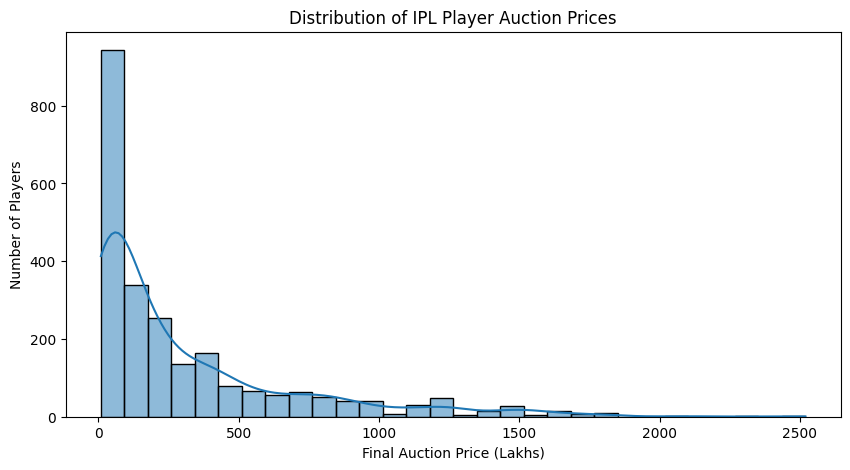

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="final_price_lakh",
    bins=30,
    kde=True
)

plt.title("Distribution of IPL Player Auction Prices")
plt.xlabel("Final Auction Price (Lakhs)")
plt.ylabel("Number of Players")
plt.show()

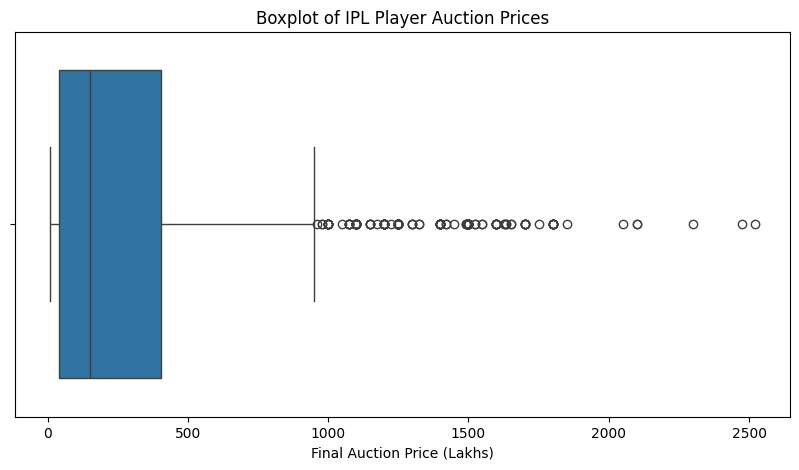

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="final_price_lakh")

plt.title("Boxplot of IPL Player Auction Prices")
plt.xlabel("Final Auction Price (Lakhs)")
plt.show()

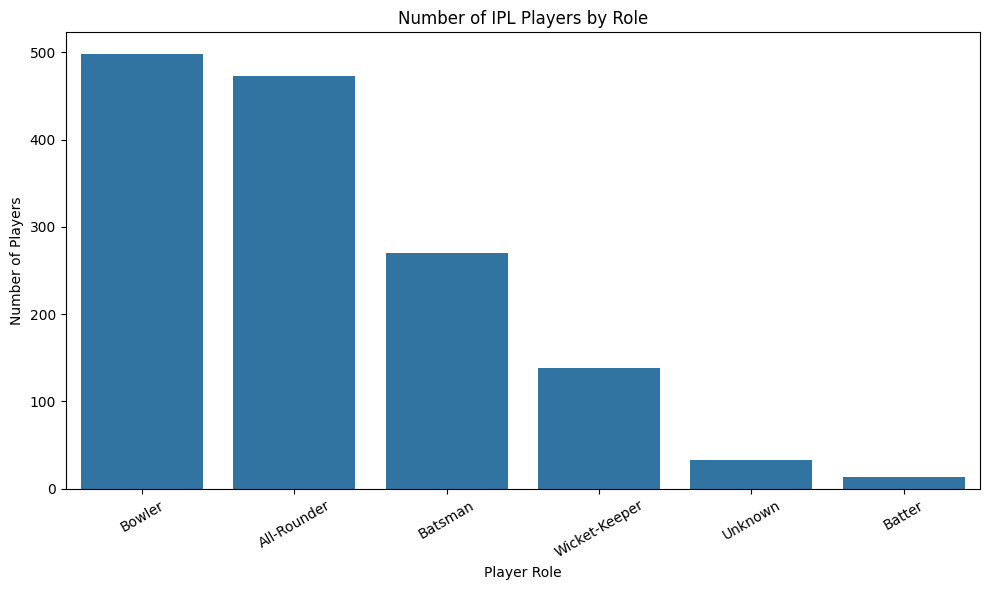

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="role",
    order=df["role"].value_counts().index
)

plt.title("Number of IPL Players by Role")
plt.xlabel("Player Role")
plt.ylabel("Number of Players")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

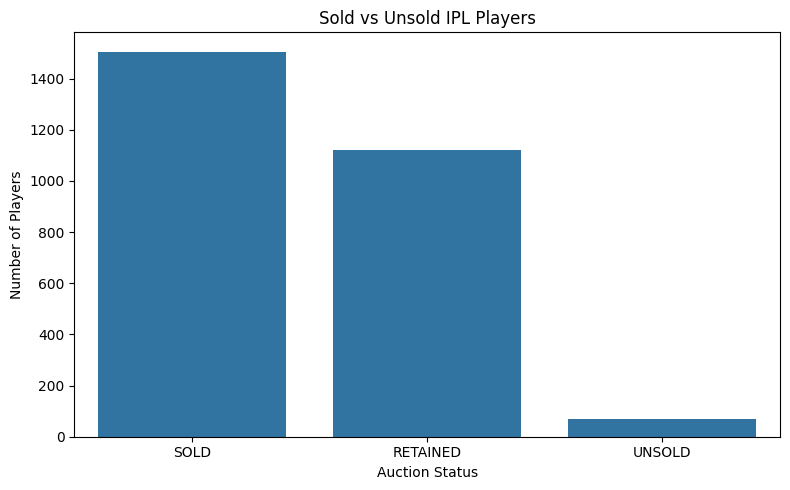

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="status")

plt.title("Sold vs Unsold IPL Players")
plt.xlabel("Auction Status")
plt.ylabel("Number of Players")
plt.tight_layout()
plt.show()

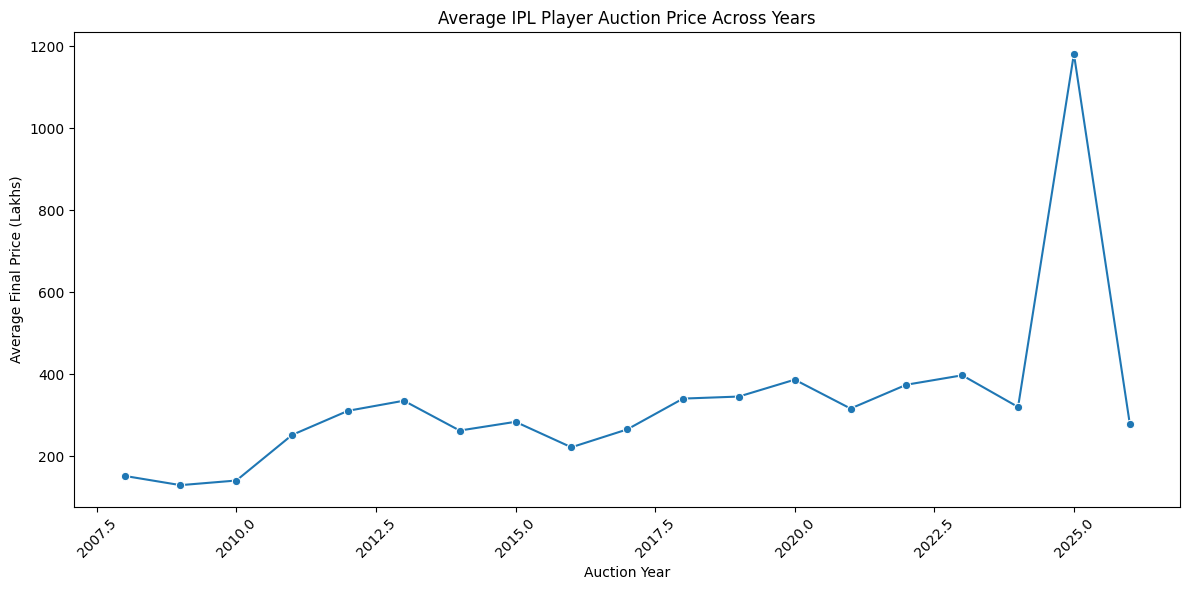

In [ ]:
yearly_prices = df.groupby("year")["final_price_lakh"].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_prices,
    x="year",
    y="final_price_lakh",
    marker="o"
)

plt.title("Average IPL Player Auction Price Across Years")
plt.xlabel("Auction Year")
plt.ylabel("Average Final Price (Lakhs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

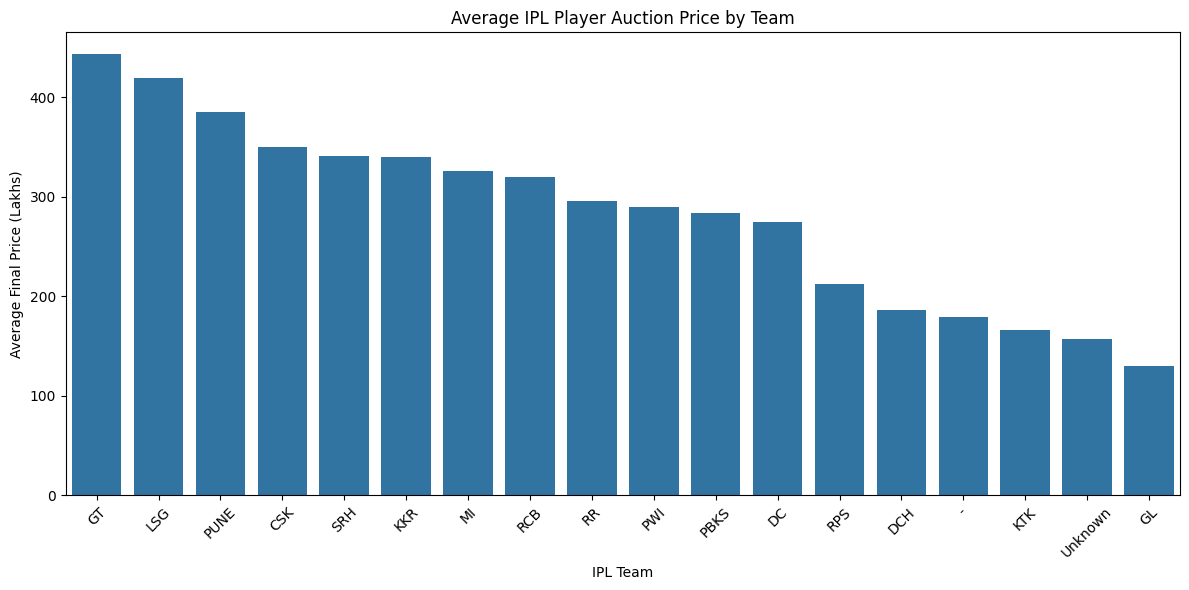

In [ ]:
team_prices = df.groupby("team")["final_price_lakh"].mean().reset_index()

team_prices = team_prices.sort_values(
    by="final_price_lakh",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_prices,
    x="team",
    y="final_price_lakh"
)

plt.title("Average IPL Player Auction Price by Team")
plt.xlabel("IPL Team")
plt.ylabel("Average Final Price (Lakhs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

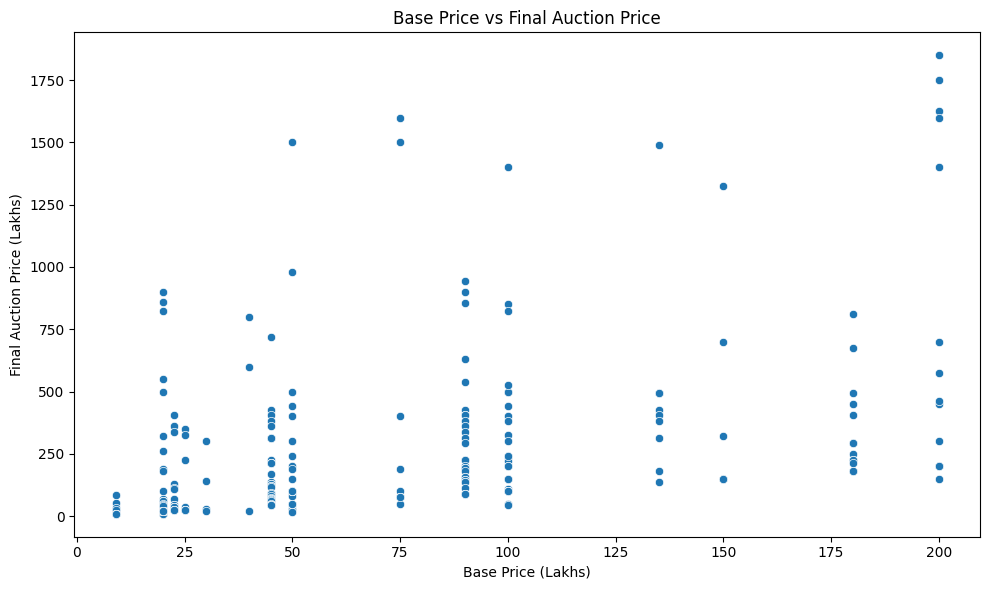

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="base_price_lakh",
    y="final_price_lakh"
)

plt.title("Base Price vs Final Auction Price")
plt.xlabel("Base Price (Lakhs)")
plt.ylabel("Final Auction Price (Lakhs)")
plt.tight_layout()
plt.show()

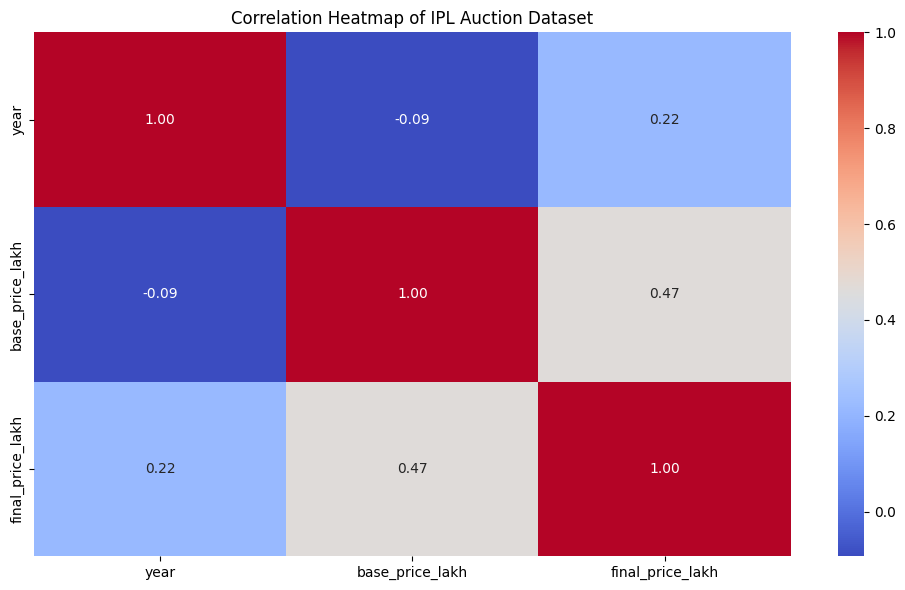

In [ ]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of IPL Auction Dataset")
plt.tight_layout()
plt.show()

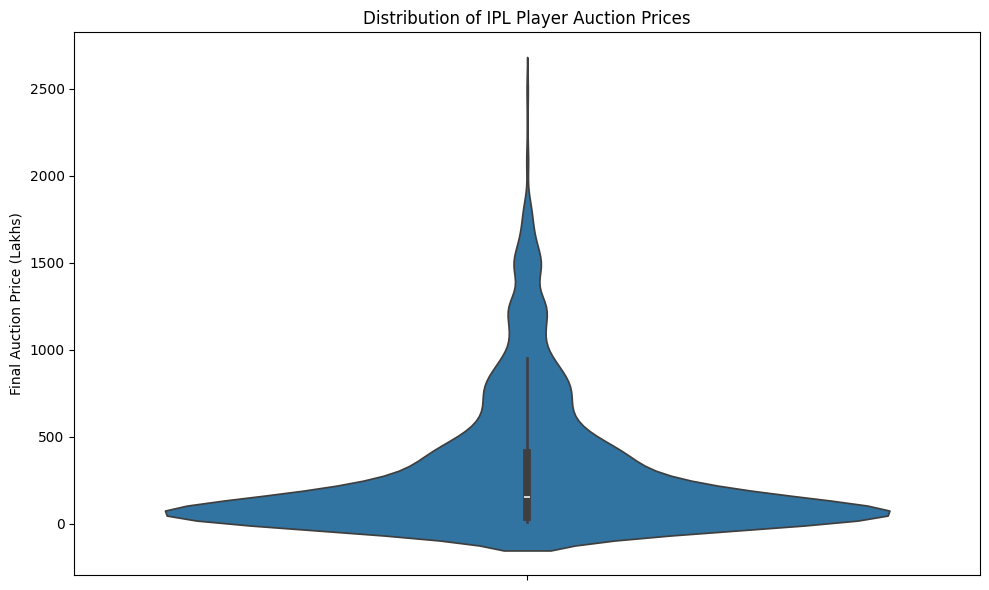

In [ ]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    y="final_price_lakh"
)

plt.title("Distribution of IPL Player Auction Prices")
plt.ylabel("Final Auction Price (Lakhs)")
plt.tight_layout()
plt.show()

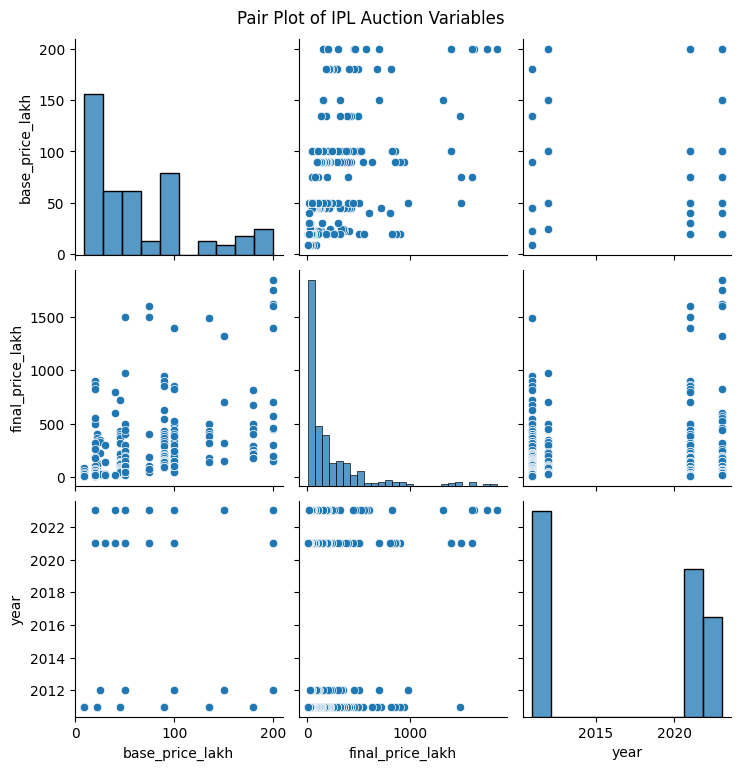

In [ ]:
pair_df = df[
    ["base_price_lakh", "final_price_lakh", "year"]
].dropna()

sns.pairplot(
    pair_df,
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of IPL Auction Variables",
    y=1.02
)

plt.show()

In [ ]:
prices = df["final_price_lakh"].dropna()

print("STATISTICAL SUMMARY OF IPL AUCTION PRICES")
print("-----------------------------------------")

print("Mean:", prices.mean())
print("Median:", prices.median())
print("Mode:", prices.mode().tolist())
print("Variance:", prices.var())
print("Standard Deviation:", prices.std())
print("Skewness:", prices.skew())
print("Kurtosis:", prices.kurtosis())

STATISTICAL SUMMARY OF IPL AUCTION PRICES
-----------------------------------------
Mean: 308.8950771798081
Median: 150.0
Mode: [20.0]
Variance: 151307.24336891077
Standard Deviation: 388.9823175530101
Skewness: 1.9085520219393843
Kurtosis: 3.673815103107171


In [ ]:
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report)

,Missing Values,Missing Percentage
base_price_lakh,2348,86.962963
role,1275,47.222222
nationality,1123,41.592593
final_price_lakh,303,11.222222
player_id,72,2.666667
player_name,0,0.000000
year,0,0.000000
team,0,0.000000
status,0,0.000000
acquisition_type,0,0.000000


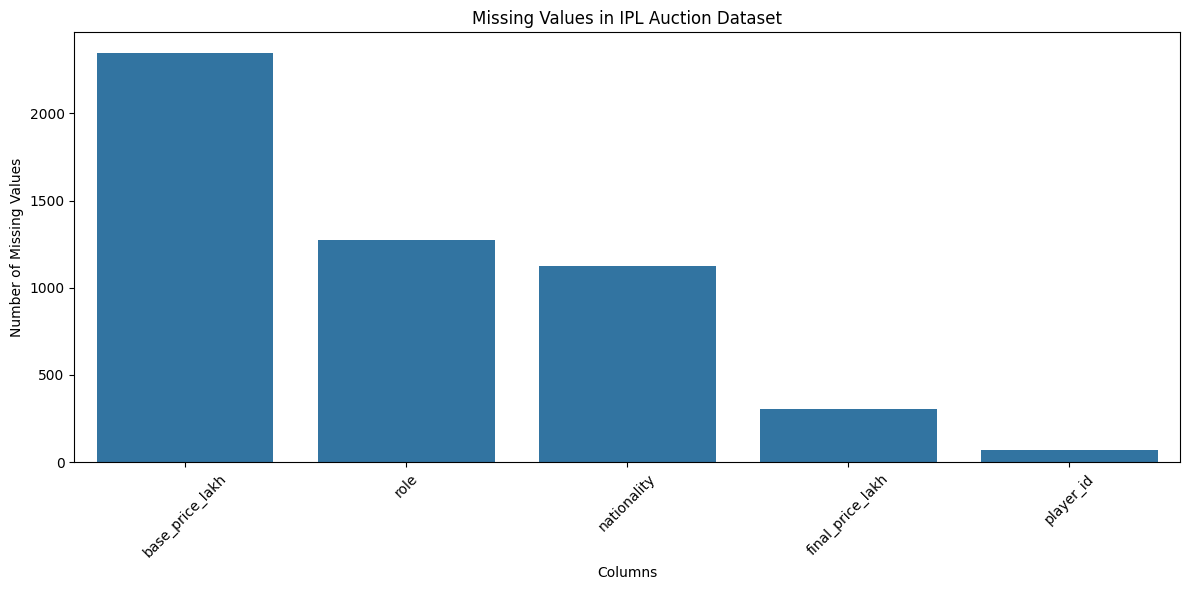

In [ ]:
plt.figure(figsize=(12, 6))

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

sns.barplot(x=missing_counts.index, y=missing_counts.values)

plt.title("Missing Values in IPL Auction Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

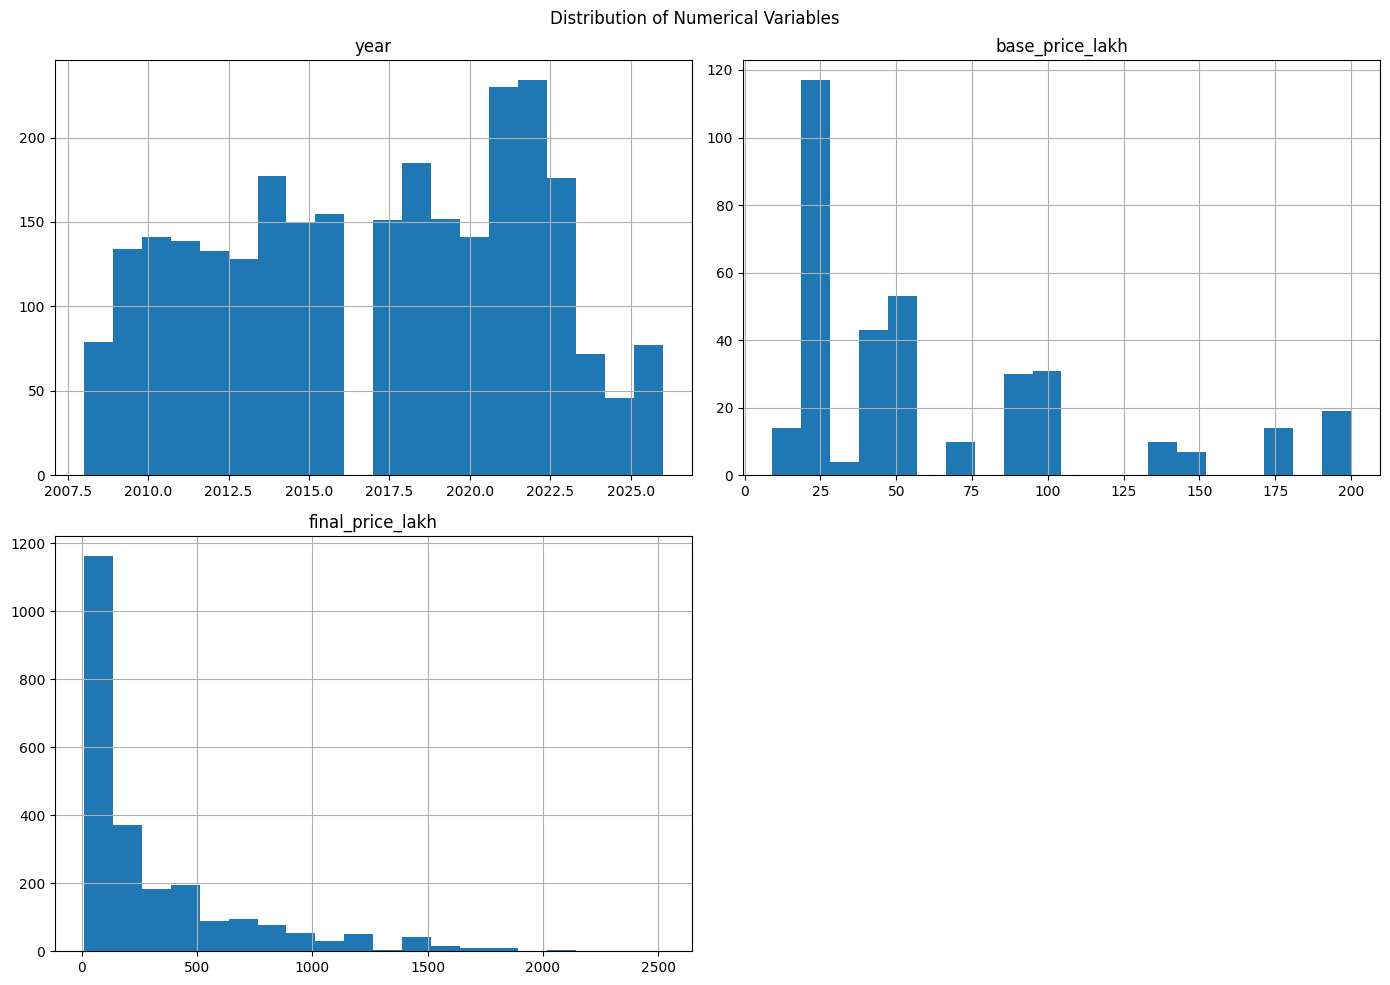

In [ ]:
numeric_columns = df.select_dtypes(include="number").columns

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

In [ ]:
numeric_summary = df.select_dtypes(include="number").agg([
    "mean",
    "median",
    "std",
    "var",
    "min",
    "max"
]).T

display(numeric_summary)

,mean,median,std,var,min,max
year,2016.946667,2017.0,4.916431,24.171293,2008.0,2026.0
base_price_lakh,63.965909,45.0,53.272270,2837.934732,9.0,200.0
final_price_lakh,308.895077,150.0,388.982318,151307.243369,9.0,2520.0


In [ ]:
shape_summary = df.select_dtypes(include="number").agg([
    "skew",
    "kurt"
]).T

shape_summary.columns = ["Skewness", "Kurtosis"]

display(shape_summary)

,Skewness,Kurtosis
year,-0.104597,-1.081289
base_price_lakh,1.276099,0.680631
final_price_lakh,1.908552,3.673815


In [ ]:
team_summary = df.groupby("team").agg(
    Total_Records=("player_name", "count"),
    Average_Final_Price=("final_price_lakh", "mean"),
    Maximum_Final_Price=("final_price_lakh", "max")
).reset_index()

team_summary = team_summary.sort_values(
    by="Average_Final_Price",
    ascending=False
)

display(team_summary)

,team,Total_Records,Average_Final_Price,Maximum_Final_Price
5,GT,58,443.148148,1800.0
8,LSG,58,419.363636,2100.0
11,PUNE,25,385.625000,900.0
1,CSK,256,350.506303,1800.0
16,SRH,230,340.783410,2300.0
6,KKR,307,340.166667,2520.0
9,MI,298,326.015038,1800.0
13,RCB,312,320.264493,2100.0
15,RR,263,295.948661,1800.0
12,PWI,17,289.632353,900.0


In [ ]:
year_summary = df.groupby("year").agg(
    Total_Records=("player_name", "count"),
    Average_Final_Price=("final_price_lakh", "mean"),
    Maximum_Final_Price=("final_price_lakh", "max")
).reset_index()

display(year_summary)

,year,Total_Records,Average_Final_Price,Maximum_Final_Price
0,2008,79,152.000000,950.0
1,2009,134,129.521930,950.0
2,2010,141,140.787815,950.0
3,2011,139,252.019928,1490.0
4,2012,133,310.776596,1490.0
5,2013,128,335.357143,1490.0
6,2014,177,262.627119,1400.0
7,2015,150,283.914729,1600.0
8,2016,155,221.830986,1250.0
9,2017,151,265.393701,1450.0


In [ ]:
prices = df["final_price_lakh"].dropna()

Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["final_price_lakh"] < lower_bound) |
    (df["final_price_lakh"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outlier Records:", len(outliers))

display(outliers.head(10))

Lower Bound: -507.5
Upper Bound: 952.5
Potential Outlier Records: 181


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source
354,2011,P0260,Gautam Gambhir,KKR,135.0,1490.0,NaN,Indian,SOLD,auction,wikipedia_excel
493,2012,P0260,G Gambhir,KKR,NaN,1490.0,NaN,NaN,RETAINED,retained,inferred_retention
494,2012,P0625,Ravindra Jadeja,CSK,50.0,978.0,NaN,Indian,SOLD,auction,wikipedia_excel
626,2013,P0260,G Gambhir,KKR,NaN,1490.0,NaN,NaN,RETAINED,retained,inferred_retention
627,2013,P0193,DA Miller,PBKS,NaN,1250.0,NaN,NaN,RETAINED,retained,inferred_retention
628,2013,P0625,RA Jadeja,CSK,NaN,978.0,NaN,NaN,RETAINED,retained,inferred_retention
754,2014,P0888,Yuvraj Singh,RCB,NaN,1400.0,All-Rounder,Indian,SOLD,auction,kaggle_main
755,2014,P0193,David Miller,PBKS,NaN,1250.0,NaN,NaN,RETAINED,retained,retained_espncricinfo
756,2014,P0236,Dinesh Karthik,DC,NaN,1250.0,Wicket-Keeper,Indian,SOLD,auction,kaggle_main
757,2014,P0260,Gautam Gambhir,KKR,NaN,1250.0,NaN,NaN,RETAINED,retained,retained_espncricinfo


In [ ]:
df.describe(include="all").to_csv("Week4_Descriptive_Statistics.csv")

missing_report.to_csv("Week4_Missing_Values_Report.csv")

numeric_summary.to_csv("Week4_Numerical_Summary.csv")

shape_summary.to_csv("Week4_Skewness_Kurtosis.csv")

team_summary.to_csv("Week4_Team_Summary.csv")

year_summary.to_csv("Week4_Year_Summary.csv")

outliers.to_csv("Week4_Potential_Outliers.csv", index=False)

print("Week 4 EDA reports saved successfully!")

Week 4 EDA reports saved successfully!


In [ ]:
from google.colab import files

report_files = [
    "Week4_Descriptive_Statistics.csv",
    "Week4_Missing_Values_Report.csv",
    "Week4_Numerical_Summary.csv",
    "Week4_Skewness_Kurtosis.csv",
    "Week4_Team_Summary.csv",
    "Week4_Year_Summary.csv",
    "Week4_Potential_Outliers.csv"
]

for file in report_files:
    files.download(file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import pandas as pd

df = pd.read_csv("/content/IPL_Auction_2008_2026_Combined.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2700, 11)


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source
0,2008,P0473,MS Dhoni,CSK,NaN,950.0,Wicket-Keeper,Indian,SOLD,auction,manual_2008
1,2008,P0011,Andrew Symonds,DCH,NaN,650.0,All-Rounder,Overseas,SOLD,auction,manual_2008
2,2008,P0709,Sanath Jayasuriya,MI,NaN,575.0,All-Rounder,Overseas,SOLD,auction,manual_2008
3,2008,P0295,Ishant Sharma,KKR,NaN,550.0,Bowler,Indian,SOLD,auction,manual_2008
4,2008,P0207,Mahela Jayawardene,DC,NaN,525.0,Batsman,Overseas,SOLD,auction,manual_2008


In [7]:
print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

DATASET SHAPE
(2700, 11)

COLUMN NAMES
['year', 'player_id', 'player_name', 'team', 'base_price_lakh', 'final_price_lakh', 'role', 'nationality', 'status', 'acquisition_type', 'source']

MISSING VALUES
year                   0
player_id             72
player_name            0
team                   0
base_price_lakh     2348
final_price_lakh     303
role                1275
nationality         1123
status                 0
acquisition_type       0
source                 0
dtype: int64

DUPLICATE ROWS
0


In [8]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage.round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
base_price_lakh,2348,86.96
role,1275,47.22
nationality,1123,41.59
final_price_lakh,303,11.22
player_id,72,2.67
player_name,0,0.00
year,0,0.00
team,0,0.00
status,0,0.00
acquisition_type,0,0.00


In [9]:
cleaning_decisions = pd.DataFrame({
    "Column": [
        "base_price_lakh",
        "final_price_lakh",
        "role",
        "nationality",
        "player_id"
    ],
    "Issue": [
        "Very high missing values",
        "Missing auction prices",
        "Missing player roles",
        "Missing nationality",
        "Missing player identifiers"
    ],
    "Planned_Action": [
        "Verify source; do not guess prices",
        "Verify source; retain missing values if unavailable",
        "Verify source; otherwise use Unknown for analysis if appropriate",
        "Verify source; otherwise use Unknown for analysis if appropriate",
        "Recover only from a reliable source"
    ]
})

display(cleaning_decisions)

,Column,Issue,Planned_Action
0,base_price_lakh,Very high missing values,Verify source; do not guess prices
1,final_price_lakh,Missing auction prices,Verify source; retain missing values if unavai...
2,role,Missing player roles,Verify source; otherwise use Unknown for analy...
3,nationality,Missing nationality,Verify source; otherwise use Unknown for analy...
4,player_id,Missing player identifiers,Recover only from a reliable source


In [11]:
import pandas as pd
import numpy as np

print("NUMERICAL COLUMNS")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCATEGORICAL COLUMNS")
print(df.select_dtypes(include="object").columns.tolist())

NUMERICAL COLUMNS
['year', 'base_price_lakh', 'final_price_lakh']

CATEGORICAL COLUMNS
['player_id', 'player_name', 'team', 'role', 'nationality', 'status', 'acquisition_type', 'source']


In [12]:
scaling_df = df[["base_price_lakh", "final_price_lakh"]].copy()

print("Missing values before scaling:")
print(scaling_df.isnull().sum())

print("\nFirst 5 rows:")
display(scaling_df.head())

Missing values before scaling:
base_price_lakh     2348
final_price_lakh     303
dtype: int64

First 5 rows:


,base_price_lakh,final_price_lakh
0,NaN,950.0
1,NaN,650.0
2,NaN,575.0
3,NaN,550.0
4,NaN,525.0


In [13]:
from sklearn.preprocessing import MinMaxScaler

price_data = df[["base_price_lakh", "final_price_lakh"]].copy()

scaler = MinMaxScaler()

normalized_prices = pd.DataFrame(
    scaler.fit_transform(price_data),
    columns=["base_price_normalized", "final_price_normalized"],
    index=price_data.index
)

print("Original Prices:")
display(price_data.head(10))

print("Normalized Prices:")
display(normalized_prices.head(10))

print("Missing values preserved:")
print(normalized_prices.isnull().sum())

Original Prices:


,base_price_lakh,final_price_lakh
0,NaN,950.0
1,NaN,650.0
2,NaN,575.0
3,NaN,550.0
4,NaN,525.0
5,NaN,375.0
6,NaN,350.0
7,NaN,300.0
8,NaN,275.0
9,NaN,275.0


Normalized Prices:


,base_price_normalized,final_price_normalized
0,NaN,0.374751
1,NaN,0.255277
2,NaN,0.225408
3,NaN,0.215452
4,NaN,0.205496
5,NaN,0.145759
6,NaN,0.135802
7,NaN,0.115890
8,NaN,0.105934
9,NaN,0.105934


Missing values preserved:
base_price_normalized     2348
final_price_normalized     303
dtype: int64


In [14]:
from sklearn.preprocessing import StandardScaler

price_data = df[["base_price_lakh", "final_price_lakh"]].copy()

scaler = StandardScaler()

standardized_prices = pd.DataFrame(
    scaler.fit_transform(price_data),
    columns=["base_price_standardized", "final_price_standardized"],
    index=price_data.index
)

print("Standardized Prices:")
display(standardized_prices.head(10))

print("\nMean of standardized columns:")
print(standardized_prices.mean().round(2))

print("\nStandard deviation:")
print(standardized_prices.std().round(2))


Standardized Prices:


,base_price_standardized,final_price_standardized
0,NaN,1.648503
1,NaN,0.877099
2,NaN,0.684248
3,NaN,0.619965
4,NaN,0.555681
5,NaN,0.169979
6,NaN,0.105695
7,NaN,-0.022872
8,NaN,-0.087156
9,NaN,-0.087156



Mean of standardized columns:
base_price_standardized    -0.0
final_price_standardized    0.0
dtype: float64

Standard deviation:
base_price_standardized     1.0
final_price_standardized    1.0
dtype: float64


In [15]:
categorical_df = df[[
    "team",
    "role",
    "nationality",
    "status"
]].copy()

print("Categorical data before encoding:")
display(categorical_df.head(10))

print("\nMissing values:")
print(categorical_df.isnull().sum())

Categorical data before encoding:


,team,role,nationality,status
0,CSK,Wicket-Keeper,Indian,SOLD
1,DCH,All-Rounder,Overseas,SOLD
2,MI,All-Rounder,Overseas,SOLD
3,KKR,Bowler,Indian,SOLD
4,DC,Batsman,Overseas,SOLD
5,DCH,Bowler,Indian,SOLD
6,PBKS,All-Rounder,Indian,SOLD
7,MI,Batsman,Indian,SOLD
8,DC,Batsman,Indian,SOLD
9,PBKS,Bowler,Indian,SOLD



Missing values:
team              0
role           1275
nationality    1123
status            0
dtype: int64


In [16]:
categorical_clean = categorical_df.copy()

categorical_clean["role"] = categorical_clean["role"].fillna("Unknown")
categorical_clean["nationality"] = categorical_clean["nationality"].fillna("Unknown")

encoded_df = pd.get_dummies(
    categorical_clean,
    columns=["team", "role", "nationality", "status"],
    dtype=int
)

print("Encoded Dataset:")
display(encoded_df.head(10))

print("\nOriginal categorical shape:", categorical_df.shape)
print("Encoded dataset shape:", encoded_df.shape)

print("\nMissing values after encoding:")
print(encoded_df.isnull().sum().sum())

Encoded Dataset:


,team_-,team_CSK,team_DC,team_DCH,team_GL,team_GT,team_KKR,team_KTK,team_LSG,team_MI,...,role_Batter,role_Bowler,role_Unknown,role_Wicket-Keeper,nationality_Indian,nationality_Overseas,nationality_Unknown,status_RETAINED,status_SOLD,status_UNSOLD
0,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,1,0
1,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
2,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,1,0
3,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,1,0,0,0,1,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
5,0,0,0,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,1,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
7,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,1,0
8,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
9,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,1,0



Original categorical shape: (2700, 4)
Encoded dataset shape: (2700, 30)

Missing values after encoding:
0


In [17]:
from sklearn.preprocessing import LabelEncoder

label_df = df[["status"]].copy()

encoder = LabelEncoder()

label_df["status_encoded"] = encoder.fit_transform(
    label_df["status"]
)

print("Original and Encoded Status:")
display(label_df.head(10))

print("\nLabel Mapping:")

for category, number in zip(
    encoder.classes_,
    encoder.transform(encoder.classes_)
):
    print(category, "=", number)

print("\nStatus counts:")
print(label_df["status"].value_counts())

Original and Encoded Status:


,status,status_encoded
0,SOLD,1
1,SOLD,1
2,SOLD,1
3,SOLD,1
4,SOLD,1
5,SOLD,1
6,SOLD,1
7,SOLD,1
8,SOLD,1
9,SOLD,1



Label Mapping:
RETAINED = 0
SOLD = 1
UNSOLD = 2

Status counts:
status
SOLD        1506
RETAINED    1123
UNSOLD        71
Name: count, dtype: int64


SKEWNESS BEFORE TRANSFORMATION
Base Price Skewness: 1.2760988405356877
Final Price Skewness: 1.9085520219393848


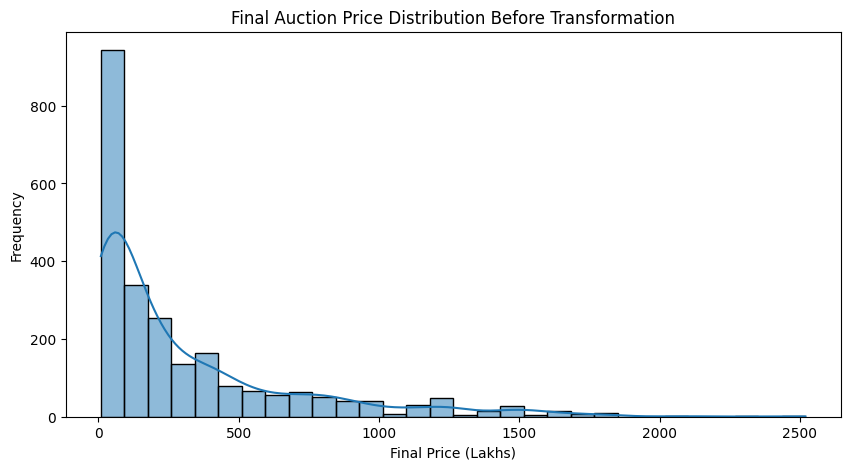

In [21]:
print("SKEWNESS BEFORE TRANSFORMATION")

print("Base Price Skewness:",
      df["base_price_lakh"].skew())

print("Final Price Skewness:",
      df["final_price_lakh"].skew())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="final_price_lakh",
    bins=30,
    kde=True
)

plt.title("Final Auction Price Distribution Before Transformation")
plt.xlabel("Final Price (Lakhs)")
plt.ylabel("Frequency")
plt.show()

Skewness Before Transformation:
1.9086

Skewness After Log Transformation:
-0.0709


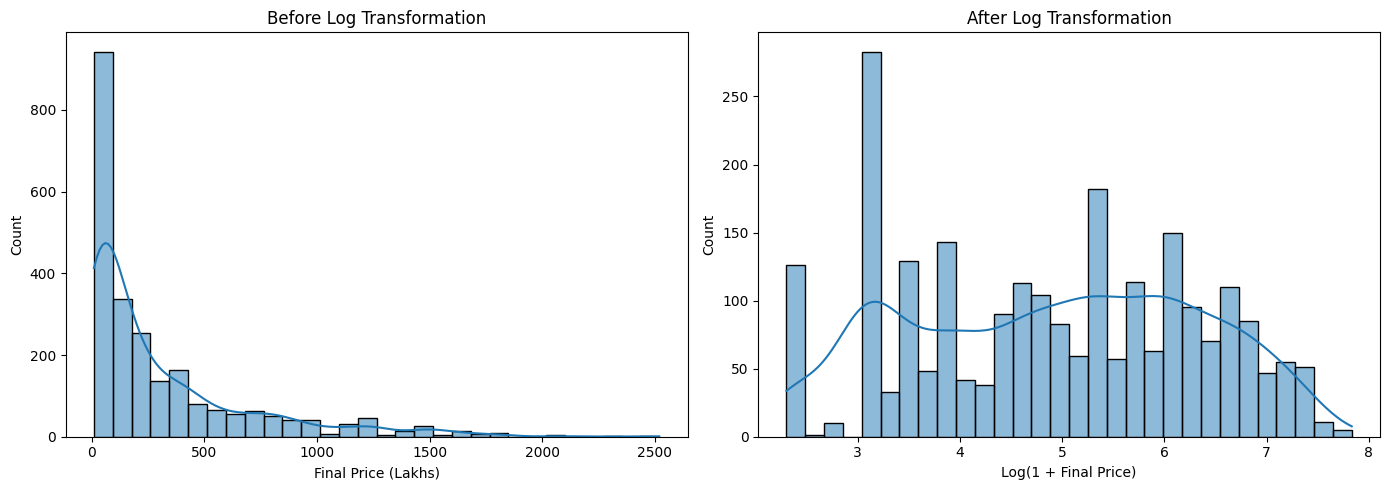

In [22]:
price_data = df["final_price_lakh"].dropna()

log_price = np.log1p(price_data)

print("Skewness Before Transformation:")
print(round(price_data.skew(), 4))

print("\nSkewness After Log Transformation:")
print(round(log_price.skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(price_data, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Before Log Transformation")
axes[0].set_xlabel("Final Price (Lakhs)")

sns.histplot(log_price, bins=30, kde=True, ax=axes[1])
axes[1].set_title("After Log Transformation")
axes[1].set_xlabel("Log(1 + Final Price)")

plt.tight_layout()
plt.show()

In [23]:
week6_df = df.copy()

week6_df["final_price_log"] = np.log1p(
    week6_df["final_price_lakh"]
)

print("Week 6 Dataset Shape:")
print(week6_df.shape)

print("\nOriginal and New Price Columns:")
display(
    week6_df[
        ["base_price_lakh", "final_price_lakh", "final_price_log"]
    ].head(10)
)

print("\nMissing Values:")
print(
    week6_df[
        ["base_price_lakh", "final_price_lakh", "final_price_log"]
    ].isnull().sum()
)

Week 6 Dataset Shape:
(2700, 12)

Original and New Price Columns:


,base_price_lakh,final_price_lakh,final_price_log
0,NaN,950.0,6.857514
1,NaN,650.0,6.478510
2,NaN,575.0,6.356108
3,NaN,550.0,6.311735
4,NaN,525.0,6.265301
5,NaN,375.0,5.929589
6,NaN,350.0,5.860786
7,NaN,300.0,5.707110
8,NaN,275.0,5.620401
9,NaN,275.0,5.620401



Missing Values:
base_price_lakh     2348
final_price_lakh     303
final_price_log      303
dtype: int64


In [24]:
week6_df.to_csv(
    "Week6_Feature_Engineered_Dataset.csv",
    index=False
)

print("Week 6 dataset saved successfully!")
print("File: Week6_Feature_Engineered_Dataset.csv")


Week 6 dataset saved successfully!
File: Week6_Feature_Engineered_Dataset.csv


In [25]:
from google.colab import files

files.download("Week6_Feature_Engineered_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>